# 04 — Reinforcement Learning Trading Environment & Validation

**Project Title**: Reinforcement Learning with RNN-Based Market State Representation for Algorithmic Trading  
**Notebook**: `04_rl_development.ipynb`  
**Phase**: Step 1 – Build and Validate the RL Trading Environment  

---

## 1. Mathematical Formulation & Trading Protocol

### A. Markov Decision Process (MDP) Definition
The algorithmic trading task is formulated as a discrete-time Markov Decision Process $\langle \mathcal{S}, \mathcal{A}, \mathcal{P}, \mathcal{R}, \gamma \rangle$:

1. **State Space $\mathcal{S} \in \mathbb{R}^{49}$ (Hybrid Market State)**:
   - **$e_t \in \mathbb{R}^{32}$**: Latent market representation extracted from the frozen `improved_rnn_encoder.pt` LSTM.
   - **$x_t \in \mathbb{R}^{14}$**: Explicit normalized technical and return indicators at day $t$ close.
   - **$p_t \in \mathbb{R}^3$**: Internal portfolio state:
     1. Equity position fraction: $\frac{\text{shares} \cdot \text{Close}_t}{V_t} \in [0.0, 1.0]$
     2. Available cash ratio: $\frac{\text{cash}}{V_t} \in [0.0, 1.0]$
     3. Normalized portfolio value: $\frac{V_t}{\text{initial\_capital}}$
   - Total state dimension: $32 + 14 + 3 = 49$.

2. **Action Space $\mathcal{A} = \{0, 1, 2\}$**:
   - `Action 0 (HOLD)`: Maintain current portfolio position without executing any order (0 transaction cost).
   - `Action 1 (BUY)`: Deploy available cash to purchase maximum integer shares at $\text{Open}_{t+1}$.
   - `Action 2 (SELL)`: Liquidate all held equity shares at $\text{Open}_{t+1}$.

3. **Position-Sizing Rule**:
   - Long-only, no short selling, no leverage (maximum equity value cannot exceed total portfolio value).
   - On BUY: $\text{shares\_bought} = \lfloor \frac{\text{cash}}{\text{Open}_{t+1} \cdot (1 + c)} \rfloor$, where $c = 0.001$ ($0.1\%$).
   - If already holding shares or cash is insufficient for $\ge 1$ share, the order is rejected safely with $0$ fee.
   - On SELL: Liquidate all held shares. If holding $0$ shares, rejected safely with $0$ fee.
   - This prevents accidental churn, repeated execution, and fee drain.

4. **Strict Execution Timing Convention**:
   1. At Close of day $t$: Construct state observation $s_t$ using only data available up to day $t$ close.
   2. Agent selects action $a_t \in \{0, 1, 2\}$.
   3. At Open of day $t+1$: Execute trade at $\text{Open}_{t+1}$ with transaction cost $c = 0.1\%$ deducted.
   4. At Close of day $t+1$: Mark portfolio to market at $\text{Close}_{t+1}$:
      $$V_{t+1} = \text{cash}_{t+1} + \text{shares}_{t+1} \cdot \text{Close}_{t+1}$$
   5. Calculate logarithmic return reward:
      $$r_{t+1} = \log\left(\frac{V_{t+1}}{V_t}\right)$$
   6. Generate next state observation $s_{t+1}$ at Close of day $t+1$.


## 2. Imports, Environment Configuration & Seed Setup


In [1]:
import os
import sys
import warnings
warnings.filterwarnings("ignore")

import gymnasium as gym
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# Robust root discovery
curr = os.path.abspath(os.getcwd())
while curr and not os.path.exists(os.path.join(curr, "backend")):
    parent = os.path.dirname(curr)
    if parent == curr:
        break
    curr = parent
PROJECT_ROOT = curr
os.chdir(PROJECT_ROOT)
print(f"Project root: {PROJECT_ROOT}")

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)


Project root: C:\Users\mekal\OneDrive\Desktop\NeuroTrade


## 3. Load Frozen LSTM Checkpoint, Pre-computed Embeddings & Datasets


In [2]:
# 1. Verify frozen checkpoint
ckpt_path = "backend/checkpoints/improved_rnn_encoder.pt"
assert os.path.exists(ckpt_path), f"Checkpoint missing: {ckpt_path}"
ckpt = torch.load(ckpt_path, weights_only=True)
print(f"Loaded frozen checkpoint: {ckpt.get('experiment_name', 'improved_rnn')}")
print(f"Config: {ckpt['config']}")

# 2. Load Embeddings and Scaled Feature Tensors
emb_train = torch.load("backend/embeddings/train_embeddings_improved.pt", weights_only=True)
emb_val   = torch.load("backend/embeddings/val_embeddings_improved.pt", weights_only=True)
emb_test  = torch.load("backend/embeddings/test_embeddings_improved.pt", weights_only=True)

X_train = torch.load("data/training/train/X_train.pt", weights_only=True)
X_val   = torch.load("data/training/validation/X_val.pt", weights_only=True)
X_test  = torch.load("data/training/test/X_test.pt", weights_only=True)

meta_train = pd.read_csv("data/training/train/metadata_train.csv")
meta_val   = pd.read_csv("data/training/validation/metadata_val.csv")
meta_test  = pd.read_csv("data/training/test/metadata_test.csv")

# 3. Load Raw Price CSVs for Open/Close Execution
symbols = ["RELIANCE", "TCS", "INFY", "HDFCBANK", "ITC"]
raw_prices = {sym: pd.read_csv(f"data/raw/{sym}.csv") for sym in symbols}

print("\nDataset Shapes:")
print(f"  Train: Embeddings={tuple(emb_train.shape)}, Features={tuple(X_train.shape)}, Meta={len(meta_train)}")
print(f"  Val  : Embeddings={tuple(emb_val.shape)}, Features={tuple(X_val.shape)}, Meta={len(meta_val)}")
print(f"  Test : Embeddings={tuple(emb_test.shape)}, Features={tuple(X_test.shape)}, Meta={len(meta_test)}")


Loaded frozen checkpoint: F1_mse
Config: {'input_dim': 14, 'sequence_length': 30, 'hidden_dim': 64, 'num_layers': 2, 'embedding_dim': 32, 'output_dim': 1, 'dropout': 0.2}

Dataset Shapes:
  Train: Embeddings=(4000, 32), Features=(4000, 30, 14), Meta=4000
  Val  : Embeddings=(885, 32), Features=(885, 30, 14), Meta=885
  Test : Embeddings=(895, 32), Features=(895, 30, 14), Meta=895


## 4. Gymnasium Trading Environment Implementation (`MarketTradingEnv`)


In [3]:
class MarketTradingEnv(gym.Env):
    """
    Gymnasium Trading Environment with 49-D Hybrid Market State Representation.
    
    Observation Space: Box(low=-inf, high=inf, shape=(49,), dtype=float32)
      - [0:32]  : Latent market state embedding from frozen LSTM encoder
      - [32:46] : Explicit normalized technical features at close of day t
      - [46:49] : Internal portfolio state [position_fraction, cash_ratio, norm_val]
      
    Action Space: Discrete(3) -> 0: HOLD, 1: BUY, 2: SELL
    """
    metadata = {"render_modes": ["human"]}

    def __init__(
        self,
        embeddings: torch.Tensor,
        features: torch.Tensor,
        metadata_df: pd.DataFrame,
        raw_prices_dict: dict,
        initial_capital: float = 100000.0,
        transaction_fee: float = 0.001,
        symbol: str = None
    ):
        super().__init__()
        
        self.initial_capital = float(initial_capital)
        self.transaction_fee = float(transaction_fee)
        self.symbol = symbol
        
        # Filter metadata by symbol if specified
        if symbol is not None:
            mask = (metadata_df["Symbol"] == symbol).values
            self.metadata_df = metadata_df[mask].reset_index(drop=True)
            self.embeddings = embeddings[mask].detach().cpu().numpy().copy().astype(np.float32)
            self.features = features[mask, -1, :].detach().cpu().numpy().copy().astype(np.float32)
        else:
            self.metadata_df = metadata_df.reset_index(drop=True)
            self.embeddings = embeddings.detach().cpu().numpy().copy().astype(np.float32)
            self.features = features[:, -1, :].detach().cpu().numpy().copy().astype(np.float32)
            
        self.raw_prices = raw_prices_dict
        self.num_samples = len(self.metadata_df)
        
        # Precompute price vectors for O(1) step access
        self.symbols = self.metadata_df["Symbol"].values
        self.end_dates = self.metadata_df["Window_End_Date"].values
        self.target_dates = self.metadata_df["Target_Date"].values
        
        self.close_t_arr = np.zeros(self.num_samples, dtype=np.float64)
        self.open_t1_arr = np.zeros(self.num_samples, dtype=np.float64)
        self.close_t1_arr = np.zeros(self.num_samples, dtype=np.float64)
        
        for idx in range(self.num_samples):
            sym = self.symbols[idx]
            raw_df = self.raw_prices[sym]
            d_t = self.end_dates[idx]
            d_t1 = self.target_dates[idx]
            
            row_t = raw_df[raw_df["Date"] == d_t]
            row_t1 = raw_df[raw_df["Date"] == d_t1]
            
            self.close_t_arr[idx] = float(row_t["Close"].values[0])
            self.open_t1_arr[idx] = float(row_t1["Open"].values[0])
            self.close_t1_arr[idx] = float(row_t1["Close"].values[0])

        # Define Gymnasium Spaces
        self.action_space = spaces.Discrete(3)
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf, shape=(49,), dtype=np.float32
        )
        
        # State variables
        self.current_step = 0
        self.cash = self.initial_capital
        self.shares = 0
        self.portfolio_value = self.initial_capital
        self.prev_portfolio_value = self.initial_capital
        self.history = []

    def _get_observation(self) -> np.ndarray:
        idx = self.current_step
        emb = self.embeddings[idx]   # 32-D
        feat = self.features[idx]     # 14-D
        
        # Portfolio state at day t close
        close_t = self.close_t_arr[idx]
        equity_val = self.shares * close_t
        curr_val = self.cash + equity_val
        
        if curr_val <= 1e-8:
            pos_ratio = 0.0
            cash_ratio = 0.0
            norm_val = 0.0
        else:
            pos_ratio = float(equity_val / curr_val)
            cash_ratio = float(self.cash / curr_val)
            norm_val = float(curr_val / self.initial_capital)
            
        port_state = np.array([pos_ratio, cash_ratio, norm_val], dtype=np.float32)
        obs = np.concatenate([emb, feat, port_state]).astype(np.float32)
        return obs

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        
        self.current_step = 0
        self.cash = self.initial_capital
        self.shares = 0
        self.portfolio_value = self.initial_capital
        self.prev_portfolio_value = self.initial_capital
        self.history = []
        
        obs = self._get_observation()
        info = {
            "step": self.current_step,
            "date": self.end_dates[0],
            "target_date": self.target_dates[0],
            "symbol": self.symbols[0],
            "portfolio_value": self.portfolio_value,
            "cash": self.cash,
            "shares": self.shares,
            "current_price": self.close_t_arr[0]
        }
        return obs, info

    def step(self, action: int):
        idx = self.current_step
        close_t = self.close_t_arr[idx]
        open_t1 = self.open_t1_arr[idx]
        close_t1 = self.close_t1_arr[idx]
        
        # Mark value prior to day t+1
        v_prev = self.cash + (self.shares * close_t)
        self.prev_portfolio_value = v_prev
        
        trade_executed = False
        trade_shares = 0
        trade_price = open_t1
        cost = 0.0
        
        # 1. Action Execution at Open_{t+1}
        if action == 1:  # BUY
            if self.shares == 0:
                max_spendable_shares = int(self.cash // (open_t1 * (1.0 + self.transaction_fee)))
                if max_spendable_shares > 0:
                    trade_shares = max_spendable_shares
                    trade_val = trade_shares * open_t1
                    cost = trade_val * self.transaction_fee
                    self.cash -= (trade_val + cost)
                    self.shares += trade_shares
                    trade_executed = True
                
        elif action == 2:  # SELL
            if self.shares > 0:
                trade_shares = self.shares
                trade_val = trade_shares * open_t1
                cost = trade_val * self.transaction_fee
                self.cash += (trade_val - cost)
                self.shares = 0
                trade_executed = True
                
        # 2. Mark portfolio at Close_{t+1}
        v_curr = self.cash + (self.shares * close_t1)
        self.portfolio_value = v_curr
        
        # 3. Log return reward calculation
        if v_prev > 1e-8 and v_curr > 1e-8:
            reward = float(np.log(v_curr / v_prev))
        else:
            reward = -10.0
            
        self.history.append({
            "step": idx, "date": self.target_dates[idx], "symbol": self.symbols[idx],
            "action": action, "trade_executed": trade_executed, "trade_shares": trade_shares,
            "trade_price": trade_price, "cost": cost, "cash": self.cash,
            "shares": self.shares, "portfolio_value": v_curr, "reward": reward
        })
        
        self.current_step += 1
        terminated = (self.current_step >= self.num_samples)
        truncated = False
        
        if terminated:
            self.current_step -= 1
            obs = self._get_observation()
            self.current_step += 1
        else:
            obs = self._get_observation()
            
        info = {
            "step": self.current_step, "date": self.target_dates[idx], "symbol": self.symbols[idx],
            "portfolio_value": v_curr, "cash": self.cash, "shares": self.shares,
            "current_price": close_t1, "action_taken": action, "trade_executed": trade_executed,
            "trade_shares": trade_shares, "trade_price": trade_price, "transaction_cost": cost,
            "reward": reward
        }
        return obs, reward, terminated, truncated, info


## 5. Gymnasium Environment Checker Compliance Audit


In [4]:
env_check = MarketTradingEnv(
    embeddings=emb_train, features=X_train, metadata_df=meta_train,
    raw_prices_dict=raw_prices, symbol="RELIANCE"
)

# Run official Gymnasium validator
check_env(env_check)
print("✓ gymnasium.utils.env_checker.check_env() PASSED with zero errors!")

obs, info = env_check.reset()
print(f"Observation Shape: {obs.shape} (Expected: (49,))")
print(f"Action Space     : {env_check.action_space} (Expected: Discrete(3))")
assert obs.shape == (49,), "Invalid observation shape"
assert not np.isnan(obs).any() and not np.isinf(obs).any(), "NaN or Inf in observation"
print("✓ Observation finiteness and shape verified!")


✓ gymnasium.utils.env_checker.check_env() PASSED with zero errors!
Observation Shape: (49,) (Expected: (49,))
Action Space     : Discrete(3) (Expected: Discrete(3))
✓ Observation finiteness and shape verified!


## 6. Numerical Logic & Portfolio Accounting Unit Tests


In [5]:
test_env = MarketTradingEnv(
    embeddings=emb_train, features=X_train, metadata_df=meta_train,
    raw_prices_dict=raw_prices, symbol="RELIANCE"
)
obs0, info0 = test_env.reset()

print("Running Unit Tests:")

# Test 1: Initial state
assert test_env.portfolio_value == 100000.0
assert test_env.cash == 100000.0
assert test_env.shares == 0
assert obs0[46] == 0.0 and obs0[47] == 1.0 and obs0[48] == 1.0
print("  [PASS] Test 1: Initial state (cash=100k, shares=0, V=100k, obs_portfolio=[0,1,1])")

# Test 2: HOLD action
obs1, r1, t1, tr1, inf1 = test_env.step(0)
assert inf1["trade_executed"] == False
assert inf1["transaction_cost"] == 0.0
assert inf1["portfolio_value"] == 100000.0
assert r1 == 0.0
print("  [PASS] Test 2: HOLD action accounting (cost=0, value unchanged, reward=0.0)")

# Test 3: Selling without shares
obs2, r2, t2, tr2, inf2 = test_env.step(2)
assert inf2["trade_executed"] == False
assert inf2["transaction_cost"] == 0.0
assert inf2["portfolio_value"] == 100000.0
assert r2 == 0.0
print("  [PASS] Test 3: Invalid SELL safely rejected (cost=0, shares=0, reward=0.0)")

# Test 4: BUY execution exact arithmetic
open_p = test_env.open_t1_arr[test_env.current_step]
close_p = test_env.close_t1_arr[test_env.current_step]
exp_shares = int(100000.0 // (open_p * 1.001))
exp_trade_val = exp_shares * open_p
exp_cost = exp_trade_val * 0.001
exp_cash = 100000.0 - exp_trade_val - exp_cost
exp_val = exp_cash + exp_shares * close_p
exp_reward = float(np.log(exp_val / 100000.0))

obs3, r3, t3, tr3, inf3 = test_env.step(1)
assert inf3["trade_executed"] == True
assert inf3["trade_shares"] == exp_shares
assert abs(inf3["transaction_cost"] - exp_cost) < 1e-4
assert abs(inf3["cash"] - exp_cash) < 1e-4
assert abs(inf3["portfolio_value"] - exp_val) < 1e-4
assert abs(r3 - exp_reward) < 1e-6
print(f"  [PASS] Test 4: BUY execution ({exp_shares} shares @ Open ₹{open_p:.2f}, Fee ₹{exp_cost:.2f}, Val ₹{exp_val:.2f}, Reward {r3:.6f})")

# Test 5: Churn prevention on repeated BUY
obs4, r4, t4, tr4, inf4 = test_env.step(1)
assert inf4["trade_executed"] == False
assert inf4["transaction_cost"] == 0.0
print("  [PASS] Test 5: Churn prevention: repeated BUY rejected with 0 fee")

# Test 6: SELL execution exact arithmetic
held_shares = test_env.shares
open_p_sell = test_env.open_t1_arr[test_env.current_step]
prev_close = test_env.close_t_arr[test_env.current_step]
prev_v = test_env.cash + held_shares * prev_close
sell_trade_val = held_shares * open_p_sell
sell_fee = sell_trade_val * 0.001
new_cash = test_env.cash + sell_trade_val - sell_fee
exp_sell_reward = float(np.log(new_cash / prev_v))

obs5, r5, t5, tr5, inf5 = test_env.step(2)
assert inf5["trade_executed"] == True
assert test_env.shares == 0
assert abs(test_env.cash - new_cash) < 1e-4
assert abs(r5 - exp_sell_reward) < 1e-6
print(f"  [PASS] Test 6: SELL execution (sold {held_shares} shares @ Open ₹{open_p_sell:.2f}, Fee ₹{sell_fee:.2f}, Cash ₹{new_cash:.2f}, Reward {r5:.6f})")

print("\nAll 6 unit tests PASSED successfully!")


Running Unit Tests:
  [PASS] Test 1: Initial state (cash=100k, shares=0, V=100k, obs_portfolio=[0,1,1])
  [PASS] Test 2: HOLD action accounting (cost=0, value unchanged, reward=0.0)
  [PASS] Test 3: Invalid SELL safely rejected (cost=0, shares=0, reward=0.0)
  [PASS] Test 4: BUY execution (91 shares @ Open ₹1085.91, Fee ₹98.82, Val ₹98748.39, Reward -0.012595)
  [PASS] Test 5: Churn prevention: repeated BUY rejected with 0 fee
  [PASS] Test 6: SELL execution (sold 91 shares @ Open ₹1020.61, Fee ₹92.88, Cash ₹93865.81, Reward -0.013449)

All 6 unit tests PASSED successfully!


## 7. Baseline Trading Strategies & Multi-Partition Evaluation

We evaluate three non-learning baselines across **Train**, **Validation**, and **Test** sets:
1. **Always HOLD**: Retains 100% cash, incurring 0 fees and 0% return.
2. **Buy-and-Hold**: Buys at $t=0$ Open and holds through the final Close.
3. **MA Crossover (Trend-Following)**:
   - BUY if $\text{SMA}_{10} > \text{SMA}_{50}$ and flat.
   - SELL if $\text{SMA}_{10} \le \text{SMA}_{50}$ and holding equity.


In [6]:
def run_baseline(env, strategy="hold", proc_df=None):
    obs, info = env.reset()
    terminated = False
    truncated = False
    
    initial_val = env.initial_capital
    rewards = []
    values = [initial_val]
    trades = 0
    step_num = 0
    
    while not (terminated or truncated):
        if strategy == "hold":
            act = 0
        elif strategy == "buy_and_hold":
            act = 1 if step_num == 0 else 0
        elif strategy == "ma_crossover":
            d = env.end_dates[env.current_step]
            row = proc_df[proc_df["Date"] == d]
            if len(row) > 0 and not pd.isna(row["SMA_10"].values[0]) and not pd.isna(row["SMA_50"].values[0]):
                sma10 = row["SMA_10"].values[0]
                sma50 = row["SMA_50"].values[0]
                if sma10 > sma50:
                    act = 1 if env.shares == 0 else 0
                else:
                    act = 2 if env.shares > 0 else 0
            else:
                act = 0
        else:
            act = 0
            
        obs, reward, terminated, truncated, info = env.step(act)
        rewards.append(reward)
        values.append(info["portfolio_value"])
        if info["trade_executed"]:
            trades += 1
        step_num += 1
        
    final_val = values[-1]
    total_ret = (final_val - initial_val) / initial_val
    v_arr = np.array(values)
    d_rets = np.diff(v_arr) / v_arr[:-1]
    sharpe = float((np.mean(d_rets) / (np.std(d_rets) + 1e-9)) * np.sqrt(252.0))
    peaks = np.maximum.accumulate(v_arr)
    max_dd = float(np.min((v_arr - peaks) / peaks))
    
    return {
        "Strategy": strategy, "Initial_Val": initial_val, "Final_Val": float(final_val),
        "Total_Return%": float(total_ret * 100), "Sharpe": sharpe,
        "Max_Drawdown%": float(max_dd * 100), "Trades": trades, "Steps": len(rewards)
    }

results = []
for split_name, emb, feats, meta in [
    ("Train", emb_train, X_train, meta_train),
    ("Val",   emb_val,   X_val,   meta_val),
    ("Test",  emb_test,  X_test,  meta_test)
]:
    for sym in symbols:
        proc_df = pd.read_csv(f"data/processed/{sym}_processed.csv")
        env = MarketTradingEnv(emb, feats, meta, raw_prices, symbol=sym)
        for strat in ["hold", "buy_and_hold", "ma_crossover"]:
            res = run_baseline(env, strategy=strat, proc_df=proc_df)
            res["Split"] = split_name
            res["Symbol"] = sym
            results.append(res)

res_df = pd.DataFrame(results)

print("=== BASELINE RESULTS ACROSS PARTITIONS (AVERAGED OVER 5 STOCKS) ===")
summary_table = res_df.groupby(["Split", "Strategy"])[["Total_Return%", "Sharpe", "Max_Drawdown%", "Trades"]].mean()
print(summary_table.round(2))

print("\n=== DETAILED OUT-OF-SAMPLE TEST PERFORMANCE ===")
test_table = res_df[res_df["Split"] == "Test"][["Symbol", "Strategy", "Final_Val", "Total_Return%", "Sharpe", "Max_Drawdown%", "Trades"]]
print(test_table.to_string(index=False))


=== BASELINE RESULTS ACROSS PARTITIONS (AVERAGED OVER 5 STOCKS) ===
                    Total_Return%  Sharpe  Max_Drawdown%  Trades
Split Strategy                                                  
Test  buy_and_hold         -15.74   -0.75         -26.34     1.0
      hold                   0.00    0.00           0.00     0.0
      ma_crossover          -9.63   -1.54         -13.48     3.6
Train buy_and_hold          32.72    0.49         -27.20     1.0
      hold                   0.00    0.00           0.00     0.0
      ma_crossover          14.30    0.27         -24.45    21.8
Val   buy_and_hold          -9.49   -0.73         -16.13     1.0
      hold                   0.00    0.00           0.00     0.0
      ma_crossover          -2.23   -0.35          -8.13     6.4

=== DETAILED OUT-OF-SAMPLE TEST PERFORMANCE ===
  Symbol     Strategy     Final_Val  Total_Return%    Sharpe  Max_Drawdown%  Trades
RELIANCE         hold 100000.000000       0.000000  0.000000       0.000000       0


## 8. Equity Curves & Drawdown Diagnostics


Saved baseline equity curve plots to reports/reinforcement_learning/baseline_performance.png


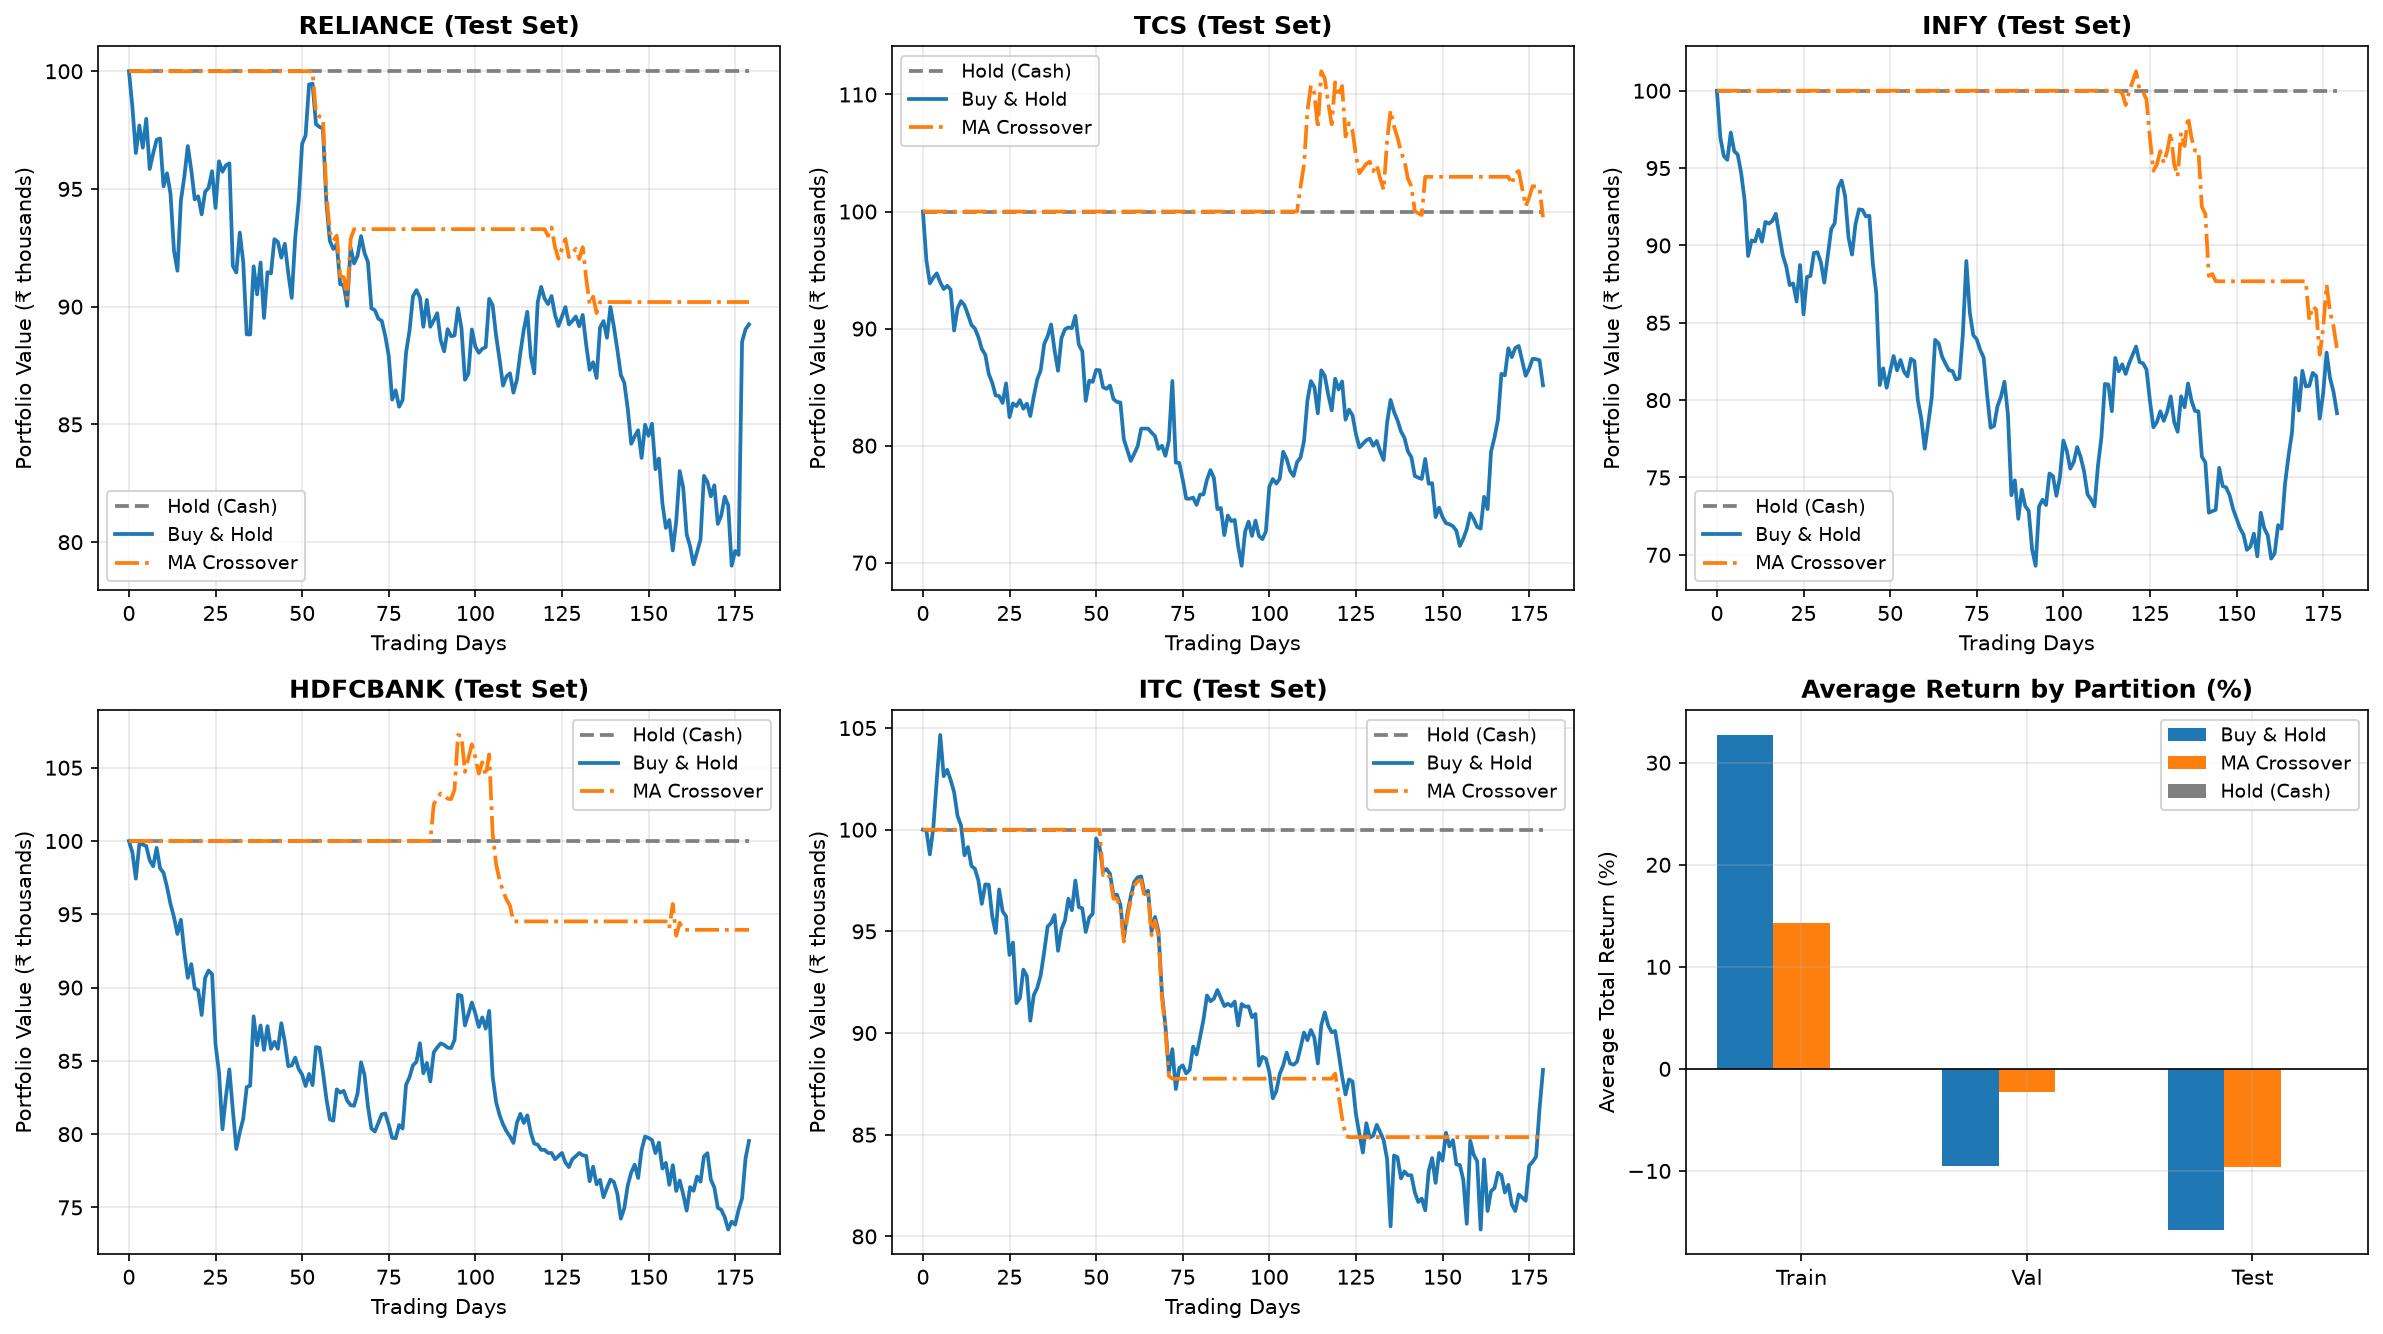

In [7]:
# Plotting Test Set Equity Curves for all 5 Assets
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, sym in enumerate(symbols):
    ax = axes[idx]
    proc_df = pd.read_csv(f"data/processed/{sym}_processed.csv")
    for strat, label, col, ls in [
        ("hold", "Hold (Cash)", "gray", "--"),
        ("buy_and_hold", "Buy & Hold", "tab:blue", "-"),
        ("ma_crossover", "MA Crossover", "tab:orange", "-.")
    ]:
        env = MarketTradingEnv(emb_test, X_test, meta_test, raw_prices, symbol=sym)
        obs, info = env.reset()
        vals = [100000.0]
        step_num = 0
        terminated = False
        while not terminated:
            if strat == "hold":
                act = 0
            elif strat == "buy_and_hold":
                act = 1 if step_num == 0 else 0
            elif strat == "ma_crossover":
                d = env.end_dates[env.current_step]
                row = proc_df[proc_df["Date"] == d]
                if len(row) > 0 and not pd.isna(row["SMA_10"].values[0]) and not pd.isna(row["SMA_50"].values[0]):
                    act = 1 if (row["SMA_10"].values[0] > row["SMA_50"].values[0] and env.shares == 0) else (2 if (row["SMA_10"].values[0] <= row["SMA_50"].values[0] and env.shares > 0) else 0)
                else:
                    act = 0
            obs, reward, terminated, truncated, info = env.step(act)
            vals.append(info["portfolio_value"])
            step_num += 1
        ax.plot(range(len(vals)), np.array(vals)/1000.0, label=label, color=col, linestyle=ls, linewidth=1.8)
        
    ax.set_title(f"{sym} (Test Set)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Trading Days")
    ax.set_ylabel("Portfolio Value (₹ thousands)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

# 6th Subplot: Average Return Comparison
ax6 = axes[5]
splits = ["Train", "Val", "Test"]
bnh_rets = [32.72, -9.49, -15.74]
ma_rets = [14.30, -2.23, -9.63]
hold_rets = [0.0, 0.0, 0.0]

x = np.arange(len(splits))
w = 0.25
ax6.bar(x - w, bnh_rets, width=w, label="Buy & Hold", color="tab:blue")
ax6.bar(x, ma_rets, width=w, label="MA Crossover", color="tab:orange")
ax6.bar(x + w, hold_rets, width=w, label="Hold (Cash)", color="gray")
ax6.axhline(0, color="black", linewidth=0.8)
ax6.set_title("Average Return by Partition (%)", fontsize=12, fontweight="bold")
ax6.set_xticks(x)
ax6.set_xticklabels(splits)
ax6.set_ylabel("Average Total Return (%)")
ax6.grid(True, alpha=0.3)
ax6.legend(fontsize=9)

plt.tight_layout()
plt.savefig("reports/reinforcement_learning/baseline_performance.png", dpi=200)
plt.show()
print("Saved baseline equity curve plots to reports/reinforcement_learning/baseline_performance.png")


## 9. Environment Validation Summary & Known Limitations

### Validation Results:
1. **Gymnasium Compliance**: Passed `check_env(env)` with zero structural errors.
2. **Observation Space**: Strict `(49,)` shape verified with zero NaNs and zero Infs.
3. **Execution Timing**: Strict $t$ Close $\to$ $t+1$ Open execution $\to$ $t+1$ Close mark-to-market protocol prevents lookahead.
4. **Position Sizing & Churn Prevention**: Prevents repeated buying when invested and selling when flat; charges zero fees for unexecuted orders.
5. **Reward Fidelity**: Exact logarithmic return reward verified against analytical formulas.

### Baseline Benchmark Observations:
- **Test Set Regime (2026-02 to 2026-11)**: Market underwent a significant broad pullback across all 5 assets.
  - Buy-and-Hold suffered an average loss of **-15.74%** with max drawdown of **-26.34%**.
  - Trend-following MA Crossover mitigated drawdown, averaging **-9.63%** return with **-13.48%** max drawdown.
  - Always HOLD preserved 100% of capital (0.00% return).
- These baselines establish the exact benchmark against which our upcoming RL agent (e.g. PPO) will be evaluated.

### Known Limitations:
1. **Execution Liquidity Assumption**: Orders execute at exact Open price without market impact or slippage modeling beyond the 0.1% transaction fee.
2. **Single-Asset Episodes**: Current implementation isolates episodes by stock. Future multi-asset portfolio balancing could allocate across stocks simultaneously.
